In [16]:
import pandas as pd
import glob
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def load_pitch_data(pattern="~/Downloads/pitch-discrimination-logs*.csv"):
    # Expand the user directory and glob pattern
    files = glob.glob(os.path.expanduser(pattern))
    
    # Read and concatenate all matching CSV files
    dfs = []
    for file in files:
        # Parse timestamps and handle quoted fields
        print(f"Loaded {file[file.rindex("/")+1:]}")
        df = pd.read_csv(file, parse_dates=['timestamp'], index_col=False)
        dfs.append(df)
    
    return pd.concat(dfs, ignore_index=True)

df = load_pitch_data()
print(f"{len(df)} records")

Loaded pitch-discrimination-logs-2024-12-17.csv
Loaded pitch-discrimination-logs-2024-12-15 (1).csv
Loaded pitch-discrimination-logs-2024-12-14.csv
Loaded pitch-discrimination-logs-2024-12-15.csv
Loaded pitch-discrimination-logs-2024-12-22 (1).csv
Loaded pitch-discrimination-logs-2024-12-18 (2).csv
Loaded pitch-discrimination-logs-2024-12-14 (1).csv
Loaded pitch-discrimination-logs-2024-12-20 (1).csv
Loaded pitch-discrimination-logs-2024-12-14 (6).csv
Loaded pitch-discrimination-logs-2024-12-17 (1).csv
Loaded pitch-discrimination-logs-2024-12-22 (4).csv
Loaded pitch-discrimination-logs-2024-12-15 (5).csv
Loaded pitch-discrimination-logs-2024-12-14 (4).csv
Loaded pitch-discrimination-logs-2024-12-17 (2).csv
Loaded pitch-discrimination-logs-2024-12-14 (5).csv
Loaded pitch-discrimination-logs-2024-12-15 (4).csv
Loaded pitch-discrimination-logs-2024-12-20 (2).csv
Loaded pitch-discrimination-logs-2024-12-22 (5).csv
Loaded pitch-discrimination-logs-2024-12-22.csv
Loaded pitch-discrimination-

/var/folders/tr/c6559c_n0xn_nvjz2lpyqxnw0000gn/T/ipykernel_32363/1154778303.py:19: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df = pd.read_csv(file, parse_dates=['timestamp'], index_col=False)
/var/folders/tr/c6559c_n0xn_nvjz2lpyqxnw0000gn/T/ipykernel_32363/1154778303.py:19: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df = pd.read_csv(file, parse_dates=['timestamp'], index_col=False)
/var/folders/tr/c6559c_n0xn_nvjz2lpyqxnw0000gn/T/ipykernel_32363/1154778303.py:19: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df = pd.read_csv(file, parse_dates=['timestamp'], index_col=False)
/var/folders/tr/c6559c_n0xn_nvjz2lpyqxnw0000gn/T/ipykernel_32363/1154778303.py:19: ParserWarning: Length of header or names does not match length of data. This leads to a loss

In [17]:
def note_to_number(note):
    """Convert a note name (e.g. 'C#4') to a numeric value for sorting"""
    # Extract the octave number
    octave = int(note[-1])
    
    # Define the order of notes within an octave
    note_order = {
        'C': 0, 'C#': 1, 
        'D': 2, 'D#': 3, 
        'E': 4, 
        'F': 5, 'F#': 6,
        'G': 7, 'G#': 8,
        'A': 9, 'A#': 10,
        'B': 11
    }
    
    # Get the note name without octave
    note_name = note[:-1]
    
    # Calculate numeric value
    return octave * 12 + note_order[note_name]

def extract_pitch_class(note):
    # Extract just the letter (and sharp if present) without the octave
    return ''.join(c for c in note if not c.isdigit())

In [18]:
def calculate_stderr(data):
    return stats.sem(data, nan_policy='omit')

def analyze_pitch_data(df):
    # Add pitch class column
    df['pitchClass'] = df['baseNote'].apply(extract_pitch_class)
    
    # Calculate accuracy by pitch with error
    pitch_accuracy = df.groupby('baseNote')['correct'].agg(['mean', 'count', 'std']).round(3)
    pitch_accuracy['stderr'] = df.groupby('baseNote')['correct'].apply(calculate_stderr)
    pitch_accuracy = pitch_accuracy.sort_index()
    
    # Calculate accuracy by pitch class with error
    pitch_class_accuracy = df.groupby('pitchClass')['correct'].agg(['mean', 'count', 'std']).round(3)
    pitch_class_accuracy['stderr'] = df.groupby('pitchClass')['correct'].apply(calculate_stderr)
    pitch_class_accuracy = pitch_class_accuracy.sort_index()
    
    # Calculate accuracy by cent difference direction with error
    cent_accuracy = df.groupby('centDifference')['correct'].agg(['mean', 'count', 'std']).round(3)
    cent_accuracy['stderr'] = df.groupby('centDifference')['correct'].apply(calculate_stderr)
    
    # Calculate average response time
    avg_response_time = df['responseTimeMs'].mean() / 1000  # Convert to seconds
    
    # Calculate overall accuracy
    overall_accuracy = df['correct'].mean()
    
    return {
        'pitch_accuracy': pitch_accuracy,
        'pitch_class_accuracy': pitch_class_accuracy,
        'cent_accuracy': cent_accuracy,
        'avg_response_time': avg_response_time,
        'overall_accuracy': overall_accuracy,
        'total_trials': len(df)
    }

In [19]:
def plot_pitch_analysis(df):
    fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(15, 18))
    
    
    # 1. Accuracy by pitch with error bars
    pitch_data = df.groupby('baseNote')['correct'].agg(['mean', 'count']).reset_index()
    pitch_data['stderr'] = df.groupby('baseNote')['correct'].apply(calculate_stderr).values
    
    # Sort by actual pitch height
    pitch_data['pitch_number'] = pitch_data['baseNote'].apply(note_to_number)
    pitch_data = pitch_data.sort_values('pitch_number')
    
    ax1.bar(range(len(pitch_data)), pitch_data['mean'])
    ax1.errorbar(range(len(pitch_data)), pitch_data['mean'], 
                yerr=pitch_data['stderr'], fmt='none', color='black', capsize=5)
    ax1.set_xticks(range(len(pitch_data)))
    ax1.set_xticklabels(pitch_data['baseNote'], rotation=45)
    ax1.set_title('Accuracy by Pitch')
    ax1.set_xlabel('Pitch')
    ax1.set_ylabel('Accuracy')
    
    # 2. Accuracy by pitch class with error bars
    pitch_class_data = df.groupby('pitchClass')['correct'].agg(['mean', 'count']).reset_index()
    pitch_class_data['stderr'] = df.groupby('pitchClass')['correct'].apply(calculate_stderr).values
    
    ax2.bar(range(len(pitch_class_data)), pitch_class_data['mean'])
    ax2.errorbar(range(len(pitch_class_data)), pitch_class_data['mean'],
                yerr=pitch_class_data['stderr'], fmt='none', color='black', capsize=5)
    ax2.set_xticks(range(len(pitch_class_data)))
    ax2.set_xticklabels(pitch_class_data['pitchClass'])
    ax2.set_title('Accuracy by Pitch Class')
    ax2.set_xlabel('Pitch Class')
    ax2.set_ylabel('Accuracy')
    
    # 3. Response time distribution
    sns.histplot(data=df, x='responseTimeMs', bins=30, ax=ax3)
    ax3.set_title('Response Time Distribution')
    ax3.set_xlabel('Response Time (ms)')
    
    # 4. Accuracy by cent difference with error bars
    cent_data = df.groupby('centDifference')['correct'].agg(['mean', 'count']).reset_index()
    cent_data['stderr'] = df.groupby('centDifference')['correct'].apply(calculate_stderr).values
    
    ax4.bar(range(len(cent_data)), cent_data['mean'])
    ax4.errorbar(range(len(cent_data)), cent_data['mean'],
                yerr=cent_data['stderr'], fmt='none', color='black', capsize=5)
    ax4.set_xticks(range(len(cent_data)))
    ax4.set_xticklabels(cent_data['centDifference'])
    ax4.set_title('Accuracy by Cent Difference')
    ax4.set_xlabel('Cent Difference')
    ax4.set_ylabel('Accuracy')
    
    # 5. Heatmap of accuracy by pitch class and cent difference
    pivot_data = pd.pivot_table(
        df,
        values='correct',
        index='pitchClass',
        columns='centDifference',
        aggfunc='mean'
    )
    
    # Create heatmap
    sns.heatmap(pivot_data, 
                annot=True,  # Show numbers in cells
                fmt='.2f',   # Format numbers to 2 decimal places
                cmap='RdYlBu',  # Red-Yellow-Blue colormap
                center=0.5,    # Center the colormap at 0.5
                ax=ax5
    )
    ax5.set_title('Accuracy by Pitch Class and Cent Difference')
    ax5.set_xlabel('Cent Difference')
    ax5.set_ylabel('Pitch Class')
    
    # 6. Additional heatmap with trial counts
    pivot_counts = pd.pivot_table(
        df,
        values='correct',
        index='pitchClass',
        columns='centDifference',
        aggfunc='count'
    )
    
    sns.heatmap(pivot_counts,
                annot=True,
                fmt='g',  # Format as integer
                cmap='Greens',
                ax=ax6
    )
    ax6.set_title('Number of Trials by Pitch Class and Cent Difference')
    ax6.set_xlabel('Cent Difference')
    ax6.set_ylabel('Pitch Class')
    
    plt.tight_layout()
    return fig



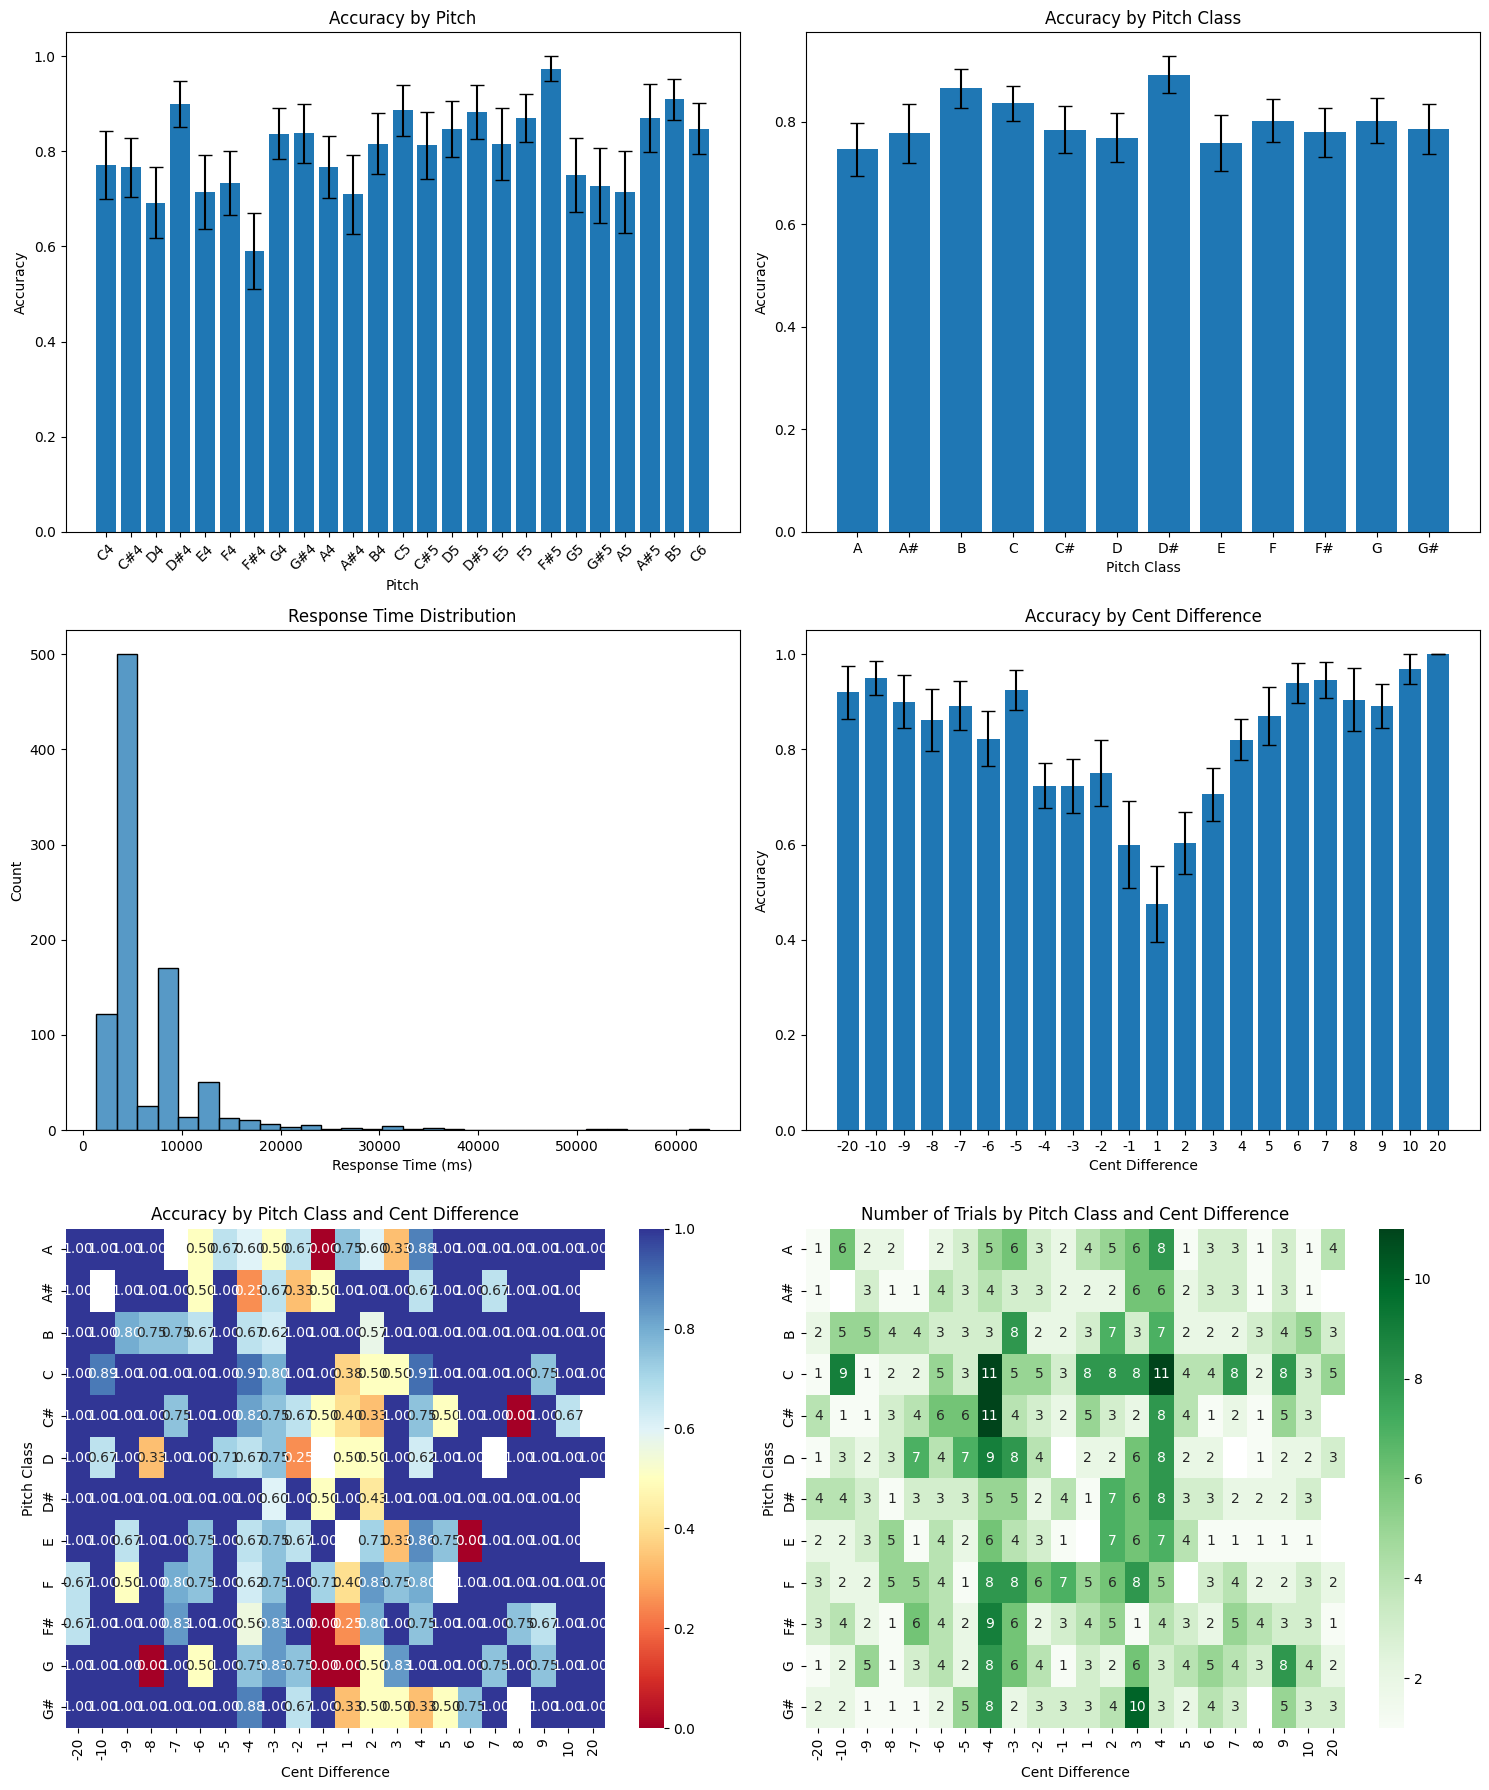

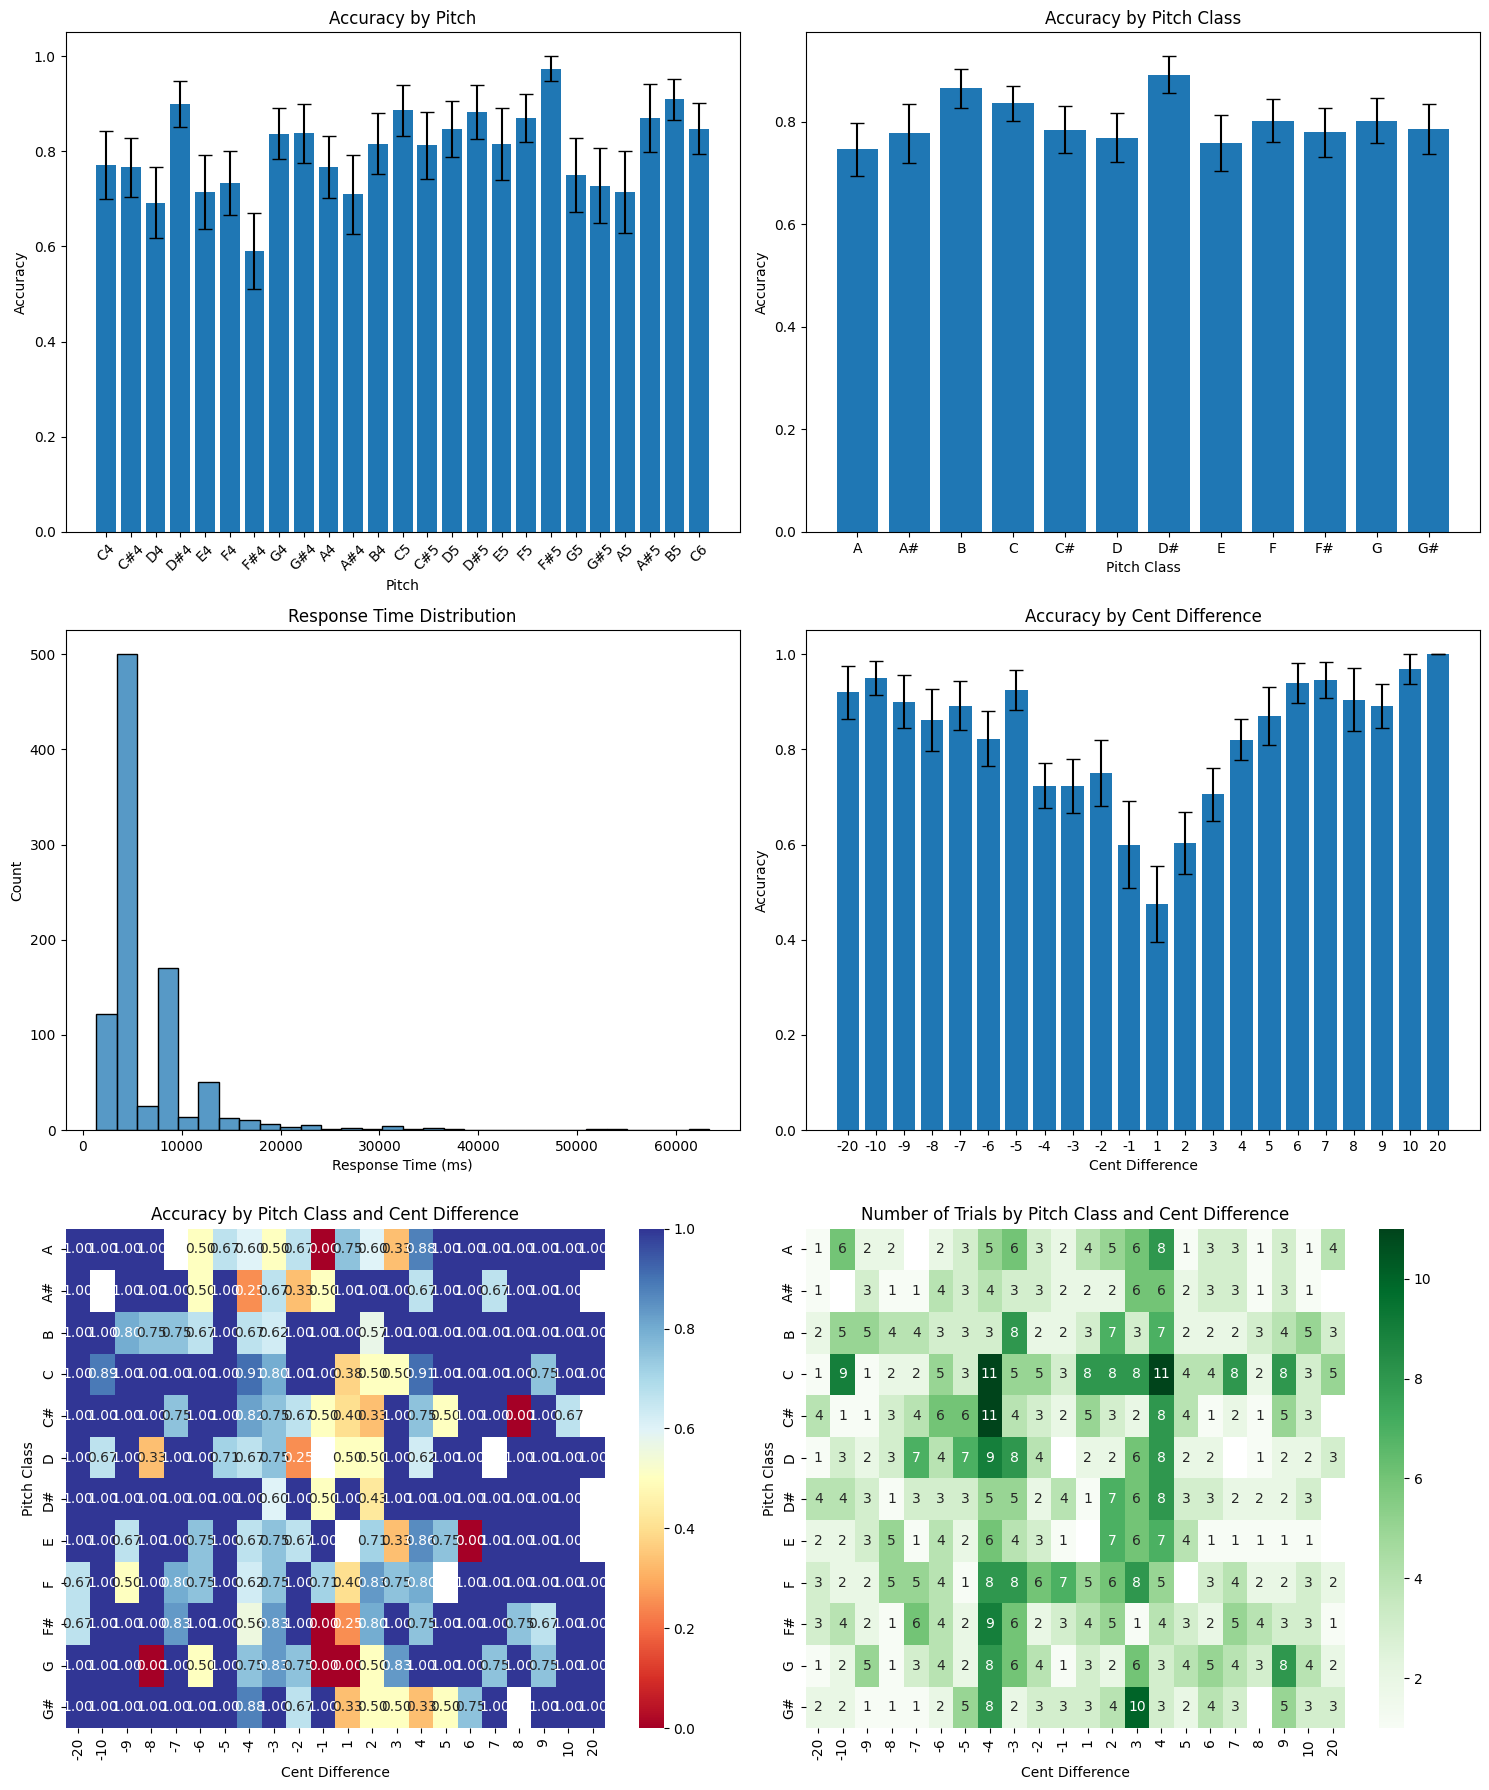

In [20]:
analyze_pitch_data(df)
plot_pitch_analysis(df)